# 02 · Load Pre-processing and Daily Peak Extraction
Goals:
1. clean telemetry glitches **without** deleting real events (Holi, the 2020 "9 pm 9 minutes" lights-off)
2. calibrate the three load sources to one measurement scale and stitch them
3. extract the **daily peak** (the target) and supporting daily statistics
4. define **critical peak days** in a growth-adjusted way
5. build state-level demand weights (used later to aggregate weather)

All logic lives in `src/heatwave_peak/load_processing.py`. The docstrings there explain each rule.

In [1]:
# --- common setup ------------------------------------------------------------
# The project code lives in src/heatwave_peak (installed with `pip install -e .`).
# If it is not installed, fall back to adding src/ to the import path.
import sys, warnings
from pathlib import Path
try:
    import heatwave_peak
except ImportError:
    sys.path.insert(0, str(Path.cwd().parent / "src"))
    import heatwave_peak
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from heatwave_peak import config as C

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

def savefig(name):
    """Save the current figure to reports/figures/<name>.png."""
    plt.savefig(C.FIGURES_DIR / f"{name}.png", bbox_inches="tight", dpi=130)

In [2]:
from heatwave_peak import load_processing as LP
a = LP.read_kaggle_hourly()["national_mw"]
b = LP.read_mendeley_hourly()
c = LP.read_scada_hourly()
for n, s in [("A kaggle", a), ("B mendeley", b), ("C scada", c)]:
    print(f"{n:<11} {s.index.min()} -> {s.index.max()}  rows={len(s):>6}  missing={s.isna().sum()}")

A kaggle    2019-01-01 00:00:00 -> 2024-04-30 23:00:00  rows= 46728  missing=0
B mendeley  2024-01-01 00:00:00 -> 2025-06-24 23:00:00  rows= 12984  missing=0
C scada     2024-11-04 00:00:00 -> 2026-09-29 23:00:00  rows= 16680  missing=464


## 1. Glitch detection: keep real events, drop sensor spikes
An hour is flagged only if it is **both** >10 % away from the average of its two neighbouring hours **and** >15 % away
from the 7-day median of the same clock hour. (Anything >30 % from that median is flagged on its own.)

*Real-life example:* on **5 April 2020 at 21:00**, the Prime Minister's "lights off for 9 minutes" appeal dropped
national demand by ~31 GW in minutes. That is real, and a naive outlier filter would delete it. Our rule keeps it, because it is
only ~10 % away from its neighbours and a one-off from the weekly profile.

flagged hours in source A: 1 [Timestamp('2021-12-17 05:00:00')]


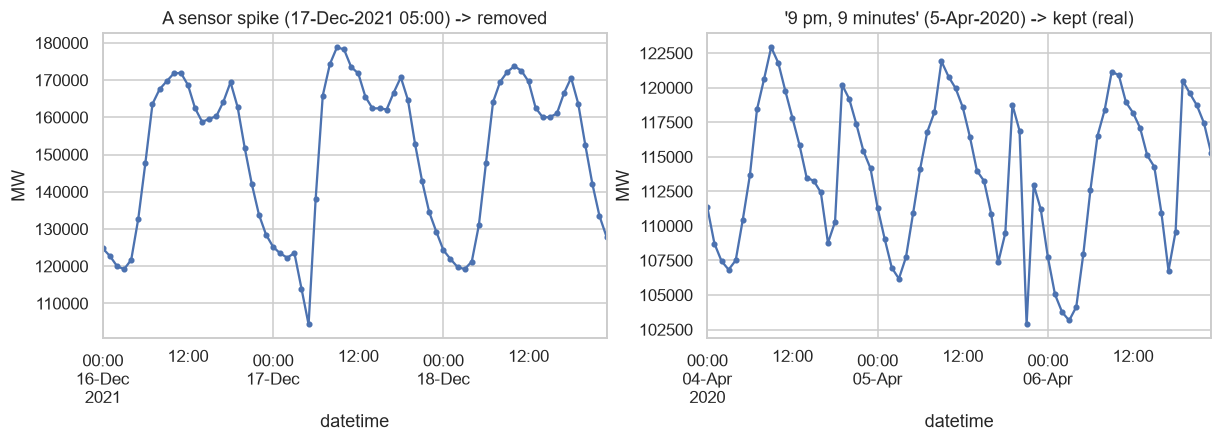

In [3]:
flags = LP.flag_spikes(a)
print("flagged hours in source A:", int(flags.sum()), list(a.index[flags]))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
a.loc["2021-12-16":"2021-12-18"].plot(ax=ax[0], marker=".", title="A sensor spike (17-Dec-2021 05:00) -> removed")
a.loc["2020-04-04":"2020-04-06"].plot(ax=ax[1], marker=".", title="'9 pm, 9 minutes' (5-Apr-2020) -> kept (real)")
for x in ax: x.set_ylabel("MW")
savefig("02_glitch_vs_real_event"); plt.show()

## 2. Calibration on the overlaps
The three sources measure the same grid with different instruments, so we compute robust (median) ratios on the overlapping hours.

A/B = 0.9923 over 2903 hours  -> B reads 0.77 % higher than A
B/C = 0.9989 over 5392 hours


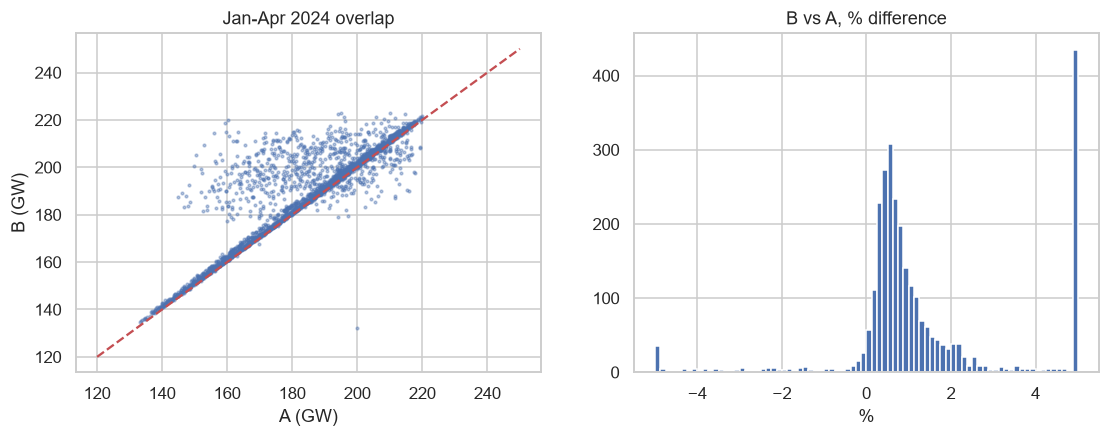

In [4]:
f_b, n_ab = LP.overlap_ratio(a, b)
f_cb, n_bc = LP.overlap_ratio(b, c)
print(f"A/B = {f_b:.4f} over {n_ab} hours  -> B reads {100*(1/f_b-1):.2f} % higher than A")
print(f"B/C = {f_cb:.4f} over {n_bc} hours")
j = pd.concat([a, b], axis=1, keys=["A", "B"]).dropna()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(j.A / 1e3, j.B / 1e3, s=3, alpha=.4); ax[0].plot([120, 250], [120, 250], "r--")
ax[0].set(xlabel="A (GW)", ylabel="B (GW)", title="Jan-Apr 2024 overlap")
(100 * (j.B / j.A - 1)).clip(-5, 5).hist(bins=80, ax=ax[1]); ax[1].set(title="B vs A, % difference", xlabel="%")
savefig("02_calibration_overlap"); plt.show()

*Why it matters:* a 0.8 % jump at the seam is ~1.6 GW at 2024 levels. That is the size of a large power station and
about a third of the model's typical error. Left in, the model would learn a fake demand surge on 1 May 2024.

## 3. Stitch A -> B -> C on A's scale

{'factor_mendeley_to_kaggle': 0.9923210295579733, 'overlap_hours_A_B': 2903, 'factor_scada_to_kaggle': 0.9912159756426763, 'overlap_hours_B_C': 5392}
source
kaggle_A      46728
scada_C        9960
mendeley_B     4680
Name: count, dtype: int64
glitches removed: 2 | short gaps interpolated: 29 | hours still missing (whole lost report days): 197


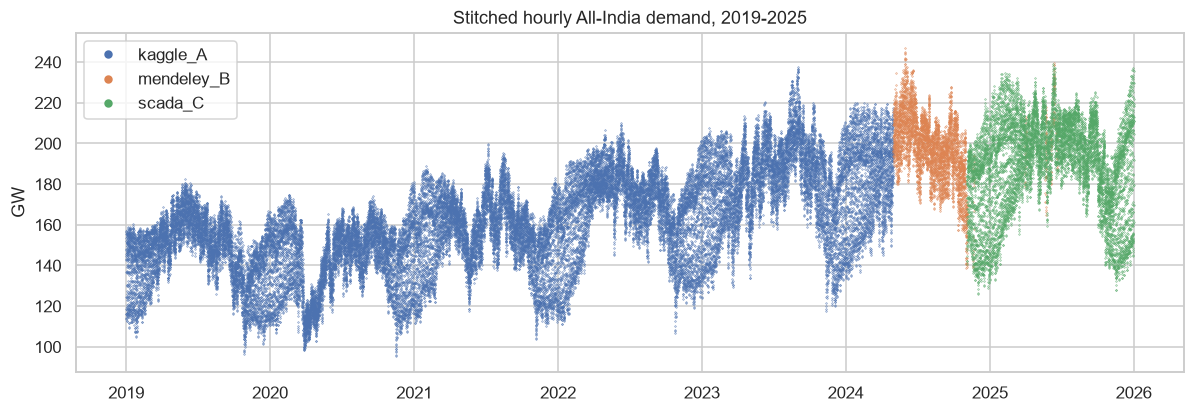

In [5]:
hourly, calib = LP.build_national_hourly()
print(calib)
print(hourly["source"].value_counts())
print("glitches removed:", int(hourly.was_glitch.sum()), "| short gaps interpolated:", int(hourly.was_filled.sum()),
      "| hours still missing (whole lost report days):", int(hourly.national_mw.isna().sum()))
fig, ax = plt.subplots(figsize=(13, 4))
for src, g in hourly.groupby("source"):
    ax.plot(g.index, g.national_mw / 1e3, ".", ms=.6, label=src)
ax.set(ylabel="GW", title="Stitched hourly All-India demand, 2019-2025"); ax.legend(markerscale=15)
savefig("02_stitched_hourly"); plt.show()

## 4. Daily peak extraction
**Target = the maximum hourly demand of the day.** Grid adequacy fails at the peak, not on daily energy.
Days with fewer than 20 valid hours (10 days, all lost NLDC report days in 2025) take NLDC's *official* daily maximum
demand met, rescaled by the median hourly-peak/instantaneous-max ratio (~0.988). They are **flagged and excluded** from
training and scoring.

In [6]:
daily = LP.build_daily_peaks(hourly)
print("PSP -> hourly-peak ratio:", round(daily.attrs["psp_to_hourly_peak_ratio"], 4))
print("imputed target days:", list(daily.index[daily.target_imputed].date))
daily.describe().T.round(1)

PSP -> hourly-peak ratio: 0.988
imputed target days: [datetime.date(2025, 6, 28), datetime.date(2025, 7, 13), datetime.date(2025, 7, 15), datetime.date(2025, 7, 29), datetime.date(2025, 8, 7), datetime.date(2025, 8, 20), datetime.date(2025, 8, 21), datetime.date(2025, 9, 9), datetime.date(2025, 10, 2), datetime.date(2025, 11, 10)]


,count,mean,std,min,25%,50%,75%,max
peak_mw,2557.0,185092.2,24801.9,112585.9,164808.6,184793.1,204737.1,246778.6
peak_hour,2547.0,13.9,5.1,0.0,10.0,11.0,19.0,23.0
min_mw,2547.0,149065.8,24202.7,95336.6,130661.8,146709.6,167858.0,210308.0
mean_mw,2547.0,168033.4,22891.4,107002.8,150492.0,167127.6,185192.1,225661.2
n_valid_hours,2557.0,23.9,1.3,0.0,24.0,24.0,24.0,24.0
solar_peak_mw,2547.0,182834.6,26029.4,111700.2,161873.0,183273.4,203417.0,246778.6
evening_peak_mw,2547.0,178508.6,21992.6,111269.7,161601.0,176461.8,195326.4,234010.2
load_factor,2547.0,0.9,0.0,0.8,0.9,0.9,0.9,1.0


In [7]:
season = daily.index.month.map(lambda m: "1 winter DJF" if m in (12, 1, 2) else "2 pre-monsoon MAM" if m in (3, 4, 5)
                               else "3 monsoon JJAS" if m in (6, 7, 8, 9) else "4 post-monsoon ON")
display(daily.groupby([daily.index.year, season]).peak_hour.median().unstack().rename_axis(None, axis=1))

,1 winter DJF,2 pre-monsoon MAM,3 monsoon JJAS,4 post-monsoon ON
date,,,,
2019,9.0,19.0,20.0,18.0
2020,9.0,15.0,20.0,18.0
2021,10.0,11.0,12.0,18.0
2022,10.0,11.0,19.0,11.0
2023,10.0,11.0,14.0,11.0
2024,10.0,11.0,15.0,11.0
2025,10.0,15.0,19.0,18.0


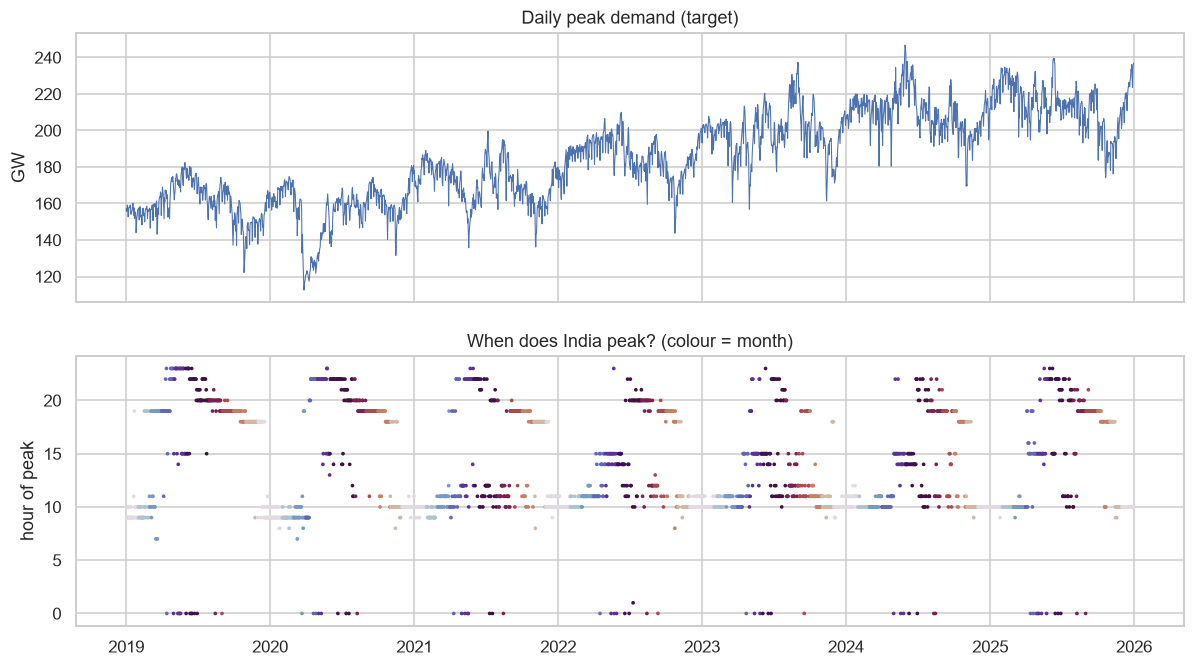

In [8]:
fig, ax = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
ax[0].plot(daily.index, daily.peak_mw / 1e3, lw=.7)
ax[0].set(ylabel="GW", title="Daily peak demand (target)")
ax[1].scatter(daily.index, daily.peak_hour, s=2, c=daily.index.month, cmap="twilight")
ax[1].set(ylabel="hour of peak", title="When does India peak? (colour = month)")
savefig("02_daily_peak_and_peak_hour"); plt.show()

The peak hour has **moved**:
* **Winter** peaks at 09-10 h every year: morning heating plus rabi-season irrigation pumps (farm feeders are often
  supplied in daytime).
* **Pre-monsoon and monsoon** peaks were at 19-20 h in 2019 (evening lighting and residential load). From 2021 they shift to
  11-15 h, and in 2023-24 the monsoon-season peak sits at 14-15 h. Day-time air-conditioning in commercial and residential
  buildings now dominates, together with agricultural load supplied during solar hours.

So the record peaks are now **afternoon heat** events. That is why the hourly ERA5 features at 15:00 (`t_15h`, `rh_15h`)
and the daily heat index matter.

## 5. Critical peak days (growth-adjusted)
A fixed MW cut-off fails because demand grows 6-8 %/yr: 220 GW was a record in 2023 and an ordinary June day in 2025.
**Critical peak day** = peak above the 90th percentile of the *previous* 365 days (uses only the past, so an operator could compute it).

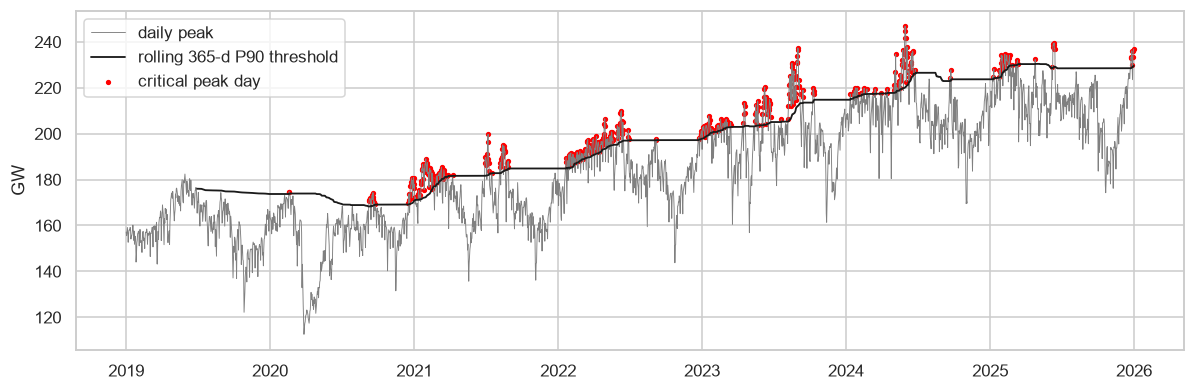

date
2019      0
2020     29
2021     89
2022    118
2023    121
2024     60
2025     45
Name: critical peak days per year, dtype: int64

In [9]:
daily = LP.add_critical_peak_flag(daily)
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(daily.index, daily.peak_mw / 1e3, lw=.6, color="grey", label="daily peak")
ax.plot(daily.index, daily.critical_peak_threshold_mw / 1e3, color="k", lw=1.2, label="rolling 365-d P90 threshold")
cp = daily[daily.is_critical_peak]
ax.scatter(cp.index, cp.peak_mw / 1e3, s=6, color="red", label="critical peak day")
ax.set(ylabel="GW"); ax.legend(); savefig("02_critical_peaks"); plt.show()
daily.groupby(daily.index.year).is_critical_peak.sum().rename("critical peak days per year")

2019 shows 0 because the threshold needs at least 180 days of history. 2020 is low because of the COVID collapse.
2021-2023 are high because demand rebounded and grew quickly, so many days beat the previous year's 90th percentile.

## 6. Regional hourly (2019-2024) and state demand weights

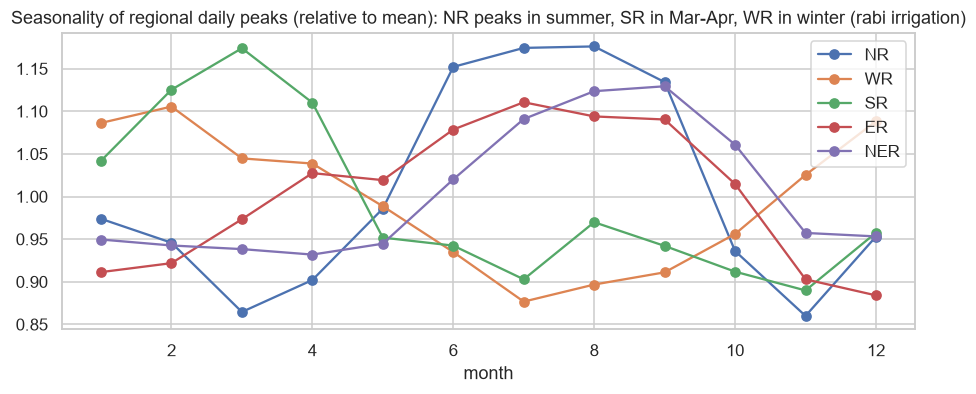

In [10]:
regional = LP.build_regional_hourly()
reg_daily_peak = regional.resample("D").max()
(reg_daily_peak.groupby(reg_daily_peak.index.month).mean() / reg_daily_peak.mean()).plot(figsize=(10, 3.5), marker="o")
plt.title("Seasonality of regional daily peaks (relative to mean): NR peaks in summer, SR in Mar-Apr, WR in winter (rabi irrigation)")
plt.xlabel("month"); savefig("02_regional_seasonality"); plt.show()

(90994, 4) | states: 33


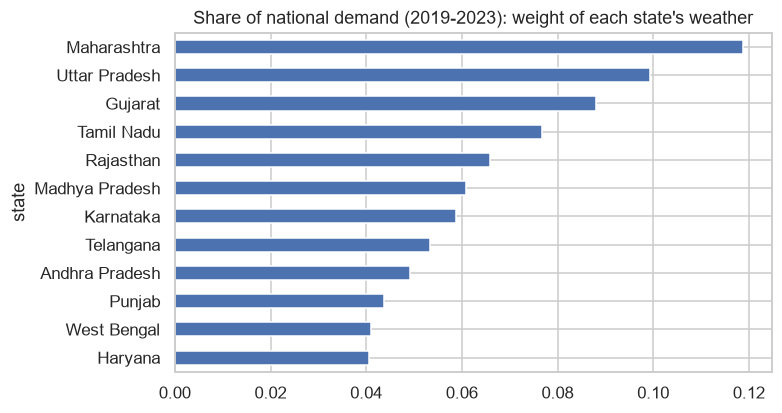

In [11]:
state_daily = LP.load_state_daily_demand()
weights = LP.state_demand_weights(state_daily)
print(state_daily.shape, "| states:", state_daily.state.nunique())
weights.head(12).plot.barh(figsize=(7, 4)); plt.gca().invert_yaxis()
plt.title("Share of national demand (2019-2023): weight of each state's weather"); savefig("02_state_weights"); plt.show()

## 7. Save interim + processed outputs

In [12]:
hourly.to_parquet(C.INTERIM_DIR / "load_hourly_national_2019_2025.parquet")
regional.to_parquet(C.INTERIM_DIR / "load_hourly_regional_2019_2024.parquet")
state_daily.to_parquet(C.INTERIM_DIR / "state_daily_demand.parquet")
d = daily.copy(); d.attrs = {}
d.to_parquet(C.PROCESSED_DIR / "daily_peak_national.parquet")
weights.to_csv(C.PROCESSED_DIR / "state_demand_weights.csv")
print("saved:", [p.name for p in C.INTERIM_DIR.glob("*.parquet")], [p.name for p in C.PROCESSED_DIR.glob("*")])

saved: ['era5_hourly_states_2018_2025.parquet', 'load_hourly_national_2019_2025.parquet', 'load_hourly_regional_2019_2024.parquet', 'state_daily_demand.parquet', 'state_daily_weather_1991_2025.parquet'] ['daily_peak_national.parquet', 'model_table.parquet', 'national_heat_exposure.parquet', 'predictions_backtest_2022_2025.parquet', 'predictions_test_2025.parquet', 'predictions_valid_2024.parquet', 'state_demand_weights.csv', 'state_signatures_and_zones.csv']
